In [1]:
import pandas as pd
from sqlalchemy import create_engine
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, accuracy_score
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt

In [2]:
DB_USER = 'root'
DB_PASSWORD = 'root'
DB_HOST = 'localhost'
DB_PORT = '3306'
DB_NAME = 'casos_tuberculose'

engine = create_engine(f"mysql+pymysql://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}")

query = """
    SELECT 
        l.regiao,
        l.indice_gini,
        t.ano_notificacao as ano,
        f.aids,
        f.alcool,
        f.diabetes,
        f.tabagismo,
        f.faixa_etaria as idade,
        f.sexo,
        f.situacao_encerramento 
    FROM fNotificacao f
    LEFT JOIN dLocal l ON f.id_ocal_esidencia = l.id_local
    LEFT JOIN dTempo t ON f.id_tempo = t.id_tempo
"""

df = pd.read_sql(query, con=engine)

In [3]:
# Remove linhas com situacao_encerramento vazio
df.dropna(subset=['situacao_encerramento'], inplace=True)

# Preenche valores nulos em outras colunas para não quebrar o modelo
df.fillna('Não Informado', inplace=True)

# Separa as variáveis preditoras (X) da variável alvo (y)
X = df.drop(columns=['situacao_encerramento'])
y = df['situacao_encerramento']

# Árvores de decisão no scikit-learn exigem dados numéricos.
# Vamos converter as colunas de texto (categóricas) em números (ex: Masculino=0, Feminino=1)
encoders = {}
for col in X.select_dtypes(include=['object']).columns:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    encoders[col] = le

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

C:\Users\kauã\AppData\Local\Temp\ipykernel_31120\760454881.py:14: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in X.select_dtypes(include=['object']).columns:


[*] Avaliando a performance na base de teste...

Acurácia Geral: 71.18%

Relatório de Classificação:


c:\Users\kauã\Desktop\projeto TCC\ia\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\kauã\Desktop\projeto TCC\ia\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\kauã\Desktop\projeto TCC\ia\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize

                         precision    recall  f1-score   support

               Abandono       0.00      0.00      0.00     11660
      Abandono Primário       0.00      0.00      0.00       728
                   Cura       0.71      1.00      0.83     64484
               Falência       0.00      0.00      0.00        70
     Mudança de Esquema       0.00      0.00      0.00       654
                  TB-DR       0.00      0.00      0.00       790
          Transferência       0.00      0.00      0.00      5379
           Óbito por TB       0.00      0.00      0.00      3183
Óbito por outras causas       0.00      0.00      0.00      3640

               accuracy                           0.71     90588
              macro avg       0.08      0.11      0.09     90588
           weighted avg       0.51      0.71      0.59     90588



[Text(0.5, 0.9, 'aids <= 2.5\ngini = 0.474\nsamples = 211371\nvalue = [27416.0, 1803.0, 149816.0, 144.0, 1509.0, 2017.0, 12539.0\n7701.0, 8426.0]\nclass = Cura'),
 Text(0.25, 0.7, 'alcool <= 1.5\ngini = 0.451\nsamples = 196472\nvalue = [24850.0, 1575.0, 142690.0, 133.0, 1224.0, 1833.0, 11174.0\n7191.0, 5802.0]\nclass = Cura'),
 Text(0.375, 0.8, 'True  '),
 Text(0.125, 0.5, 'idade <= 5.5\ngini = 0.421\nsamples = 161679\nvalue = [18202.0, 1220.0, 121177.0, 100.0, 1036.0, 1463.0, 8892.0\n5052.0, 4537.0]\nclass = Cura'),
 Text(0.0625, 0.3, 'alcool <= 0.5\ngini = 0.403\nsamples = 133461\nvalue = [16787, 1055, 101377, 74, 741, 1218, 7504, 2640, 2065]\nclass = Cura'),
 Text(0.03125, 0.1, 'gini = 0.55\nsamples = 10318\nvalue = [1820.0, 107.0, 6577.0, 7.0, 34.0, 90.0, 1034.0, 381.0\n268.0]\nclass = Cura'),
 Text(0.09375, 0.1, 'gini = 0.389\nsamples = 123143\nvalue = [14967, 948, 94800, 67, 707, 1128, 6470, 2259, 1797]\nclass = Cura'),
 Text(0.1875, 0.3, 'tabagismo <= 0.5\ngini = 0.488\nsamples 

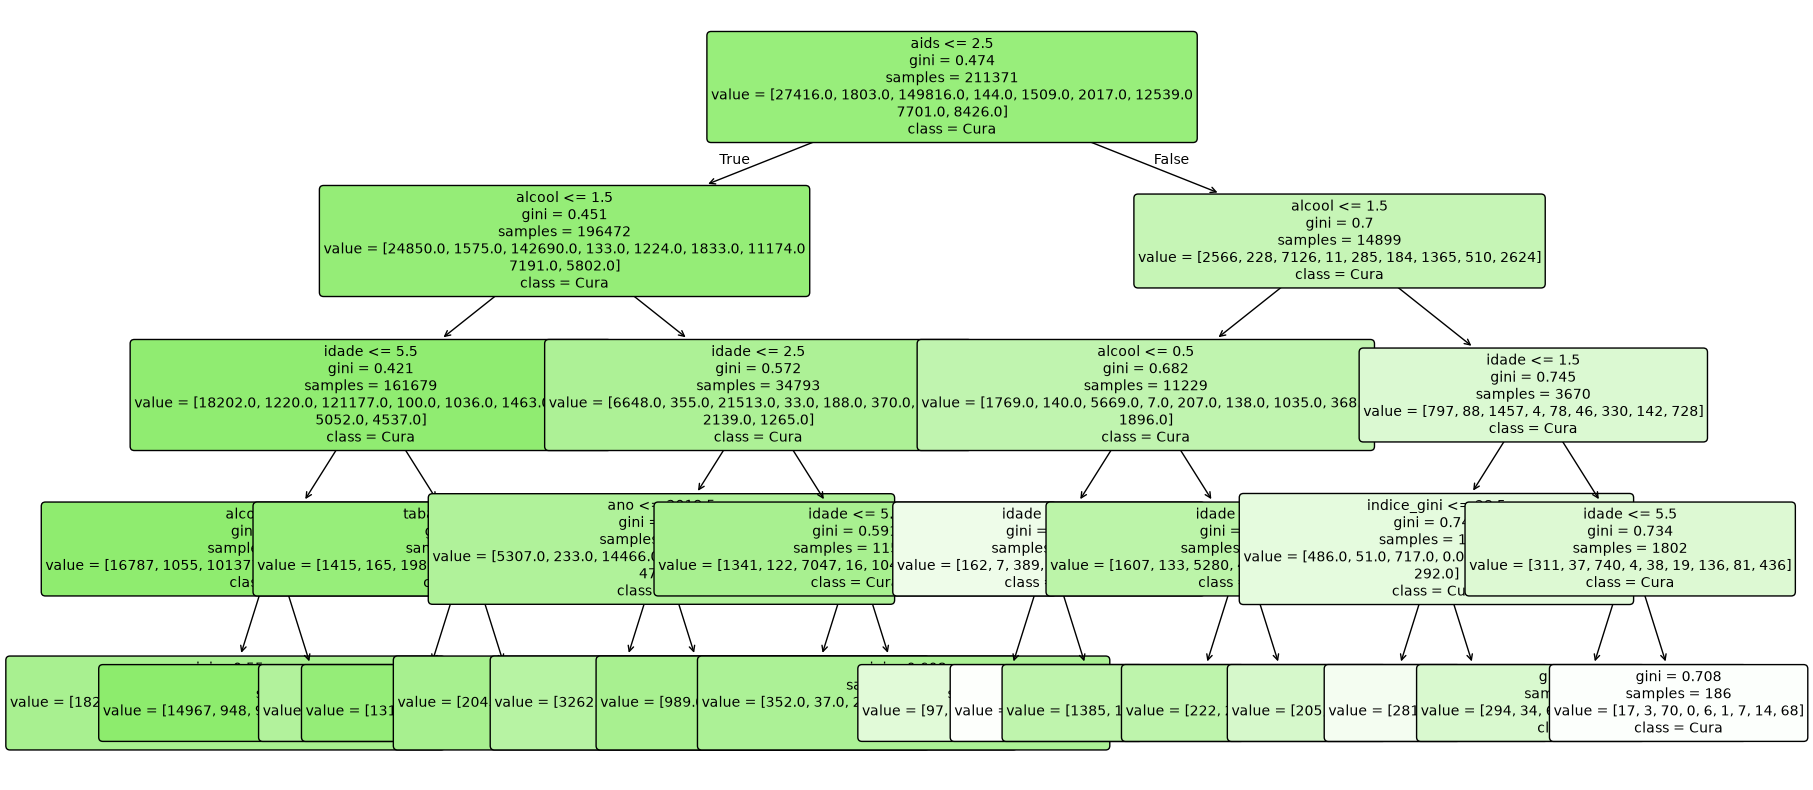

In [4]:
modelo_arvore = DecisionTreeClassifier(max_depth=4, random_state=42, criterion='gini')
modelo_arvore.fit(X_train, y_train)

# ==========================================
# 4. Avaliação do Modelo
# ==========================================
print("[*] Avaliando a performance na base de teste...\n")
previsoes = modelo_arvore.predict(X_test)

print(f"Acurácia Geral: {accuracy_score(y_test, previsoes) * 100:.2f}%\n")
print("Relatório de Classificação:")
print(classification_report(y_test, previsoes))

# ==========================================
# 5. Visualização Clínica da Árvore
# ==========================================
plt.figure(figsize=(20, 10))
plot_tree(
    modelo_arvore, 
    feature_names=X.columns, 
    class_names=modelo_arvore.classes_.astype(str),
    filled=True, 
    rounded=True, 
    fontsize=10
)